# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Mai Mariam


- **Student ID:** 023-24-0140


- **Section:** E

- **GitHub:**
-

- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [2]:
from google.colab import files
files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


{'WA_Fn-UseC_-Telco-Customer-Churn.csv': b'customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn\n7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No\n5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No\n3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes\n7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No\n9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes\n9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes

In [3]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve, average_precision_score)

RANDOM_STATE = 42   # same random_state as Labs 3/4/6

# Load and clean
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Raw shape:', df.shape)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges:', df['TotalCharges'].isna().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})
print(df['Churn'].value_counts(normalize=True).round(3))
df.head()

Raw shape: (7043, 21)
Missing TotalCharges: 11
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [6]:
df_enc = pd.get_dummies(df, drop_first=True)
X = df_enc.drop(columns=['Churn'])
y = df_enc['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Features:', X.shape[1], '| Train:', X_train.shape, '| Test:', X_test.shape)

def get_metrics(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred)}

Features: 30 | Train: (5634, 30) | Test: (1409, 30)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [7]:
# Unscaled linear SVM (max_iter capped so a non-converging run can't hang; warning is captured)
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter('always')
    svm_raw = SVC(kernel='linear', random_state=RANDOM_STATE, max_iter=2_000_000)
    t0 = time.time()
    svm_raw.fit(X_train, y_train)
    t_raw = time.time() - t0
pred_raw = svm_raw.predict(X_test)
m_raw = get_metrics(y_test, pred_raw)
print('UNSCALED  ->', {k: round(v, 4) for k, v in m_raw.items()})
print('Training time: %.2f s' % t_raw)
print('Warnings:', [str(w.message)[:90] for w in w_raw] or 'none')

UNSCALED  -> {'Accuracy': 0.5976, 'Precision': 0.3683, 'Recall': 0.7219, 'F1': 0.4878}
Training time: 59.34 s
Warnings: ['Solver terminated early (max_iter=2000000).  Consider pre-processing your data with Standa']


In [8]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s = scaler.transform(X_test)

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter('always')
    svm_s = SVC(kernel='linear', random_state=RANDOM_STATE, max_iter=2_000_000)
    t0 = time.time()
    svm_s.fit(X_train_s, y_train)
    t_s = time.time() - t0
pred_s = svm_s.predict(X_test_s)
m_s = get_metrics(y_test, pred_s)
print('SCALED    ->', {k: round(v, 4) for k, v in m_s.items()})
print('Training time: %.2f s' % t_s)
print('Warnings:', [str(w.message)[:90] for w in w_s] or 'none')

pd.DataFrame({'Unscaled': {**m_raw, 'Train time (s)': t_raw},
              'Scaled': {**m_s, 'Train time (s)': t_s}}).round(4)

SCALED    -> {'Accuracy': 0.7892, 'Precision': 0.6207, 'Recall': 0.5294, 'F1': 0.5714}
Training time: 1.84 s
Warnings: none


,Unscaled,Scaled
Accuracy,0.5976,0.7892
Precision,0.3683,0.6207
Recall,0.7219,0.5294
F1,0.4878,0.5714
Train time (s),59.3362,1.8359


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* Scaling made a big difference. The unscaled model got accuracy 0.598 and F1 0.488 (precision only 0.368), took about 23.5 s, and its solver stopped early at the max_iter cap (2,000,000) without converging, which raised a warning. The scaled model got accuracy 0.789 and F1 0.571 (precision 0.621), trained in about 0.7 s (roughly 30x faster), and gave no warnings.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* The SVM maximises the margin, which depends on distances (dot products) between points and on the norm of the weight vector. TotalCharges (up to about 8,000) and tenure/MonthlyCharges are on much larger scales than the 0/1 one-hot columns, so they dominate the distance calculation and the margin is stretched along those axes. The binary features barely influence the boundary, and the optimisation problem becomes badly conditioned, so the solver needs many more iterations and may not converge. The resulting hyperplane is poor, which explains the low accuracy.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* The scaled version (StandardScaler fitted on the training data only, then applied to the test data) for every SVM. It trains faster, converges, and performs clearly better. Fitting on train only also avoids data leakage. RBF and polynomial kernels are even more sensitive to feature scale than the linear kernel.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [9]:
kernels = ['linear', 'rbf', 'poly']
models, results = {}, {}
for k in kernels:
    t0 = time.time()
    mdl = SVC(kernel=k, random_state=RANDOM_STATE)
    mdl.fit(X_train_s, y_train)
    tt = time.time() - t0
    pred = mdl.predict(X_test_s)
    r = get_metrics(y_test, pred)
    r['Support Vectors'] = mdl.support_.shape[0]
    r['Train time (s)'] = tt
    models[k], results[k] = mdl, r
    print(k, 'done')

linear done
rbf done
poly done


In [10]:
kernel_df = pd.DataFrame(results).T.round(4)
kernel_df['Support Vectors'] = kernel_df['Support Vectors'].astype(int)
kernel_df

,Accuracy,Precision,Recall,F1,Support Vectors,Train time (s)
linear,0.7892,0.6207,0.5294,0.5714,2569,1.8361
rbf,0.7928,0.6444,0.4893,0.5562,2661,1.6719
poly,0.7892,0.6421,0.4652,0.5395,2739,1.7228


Best kernel by F1: linear


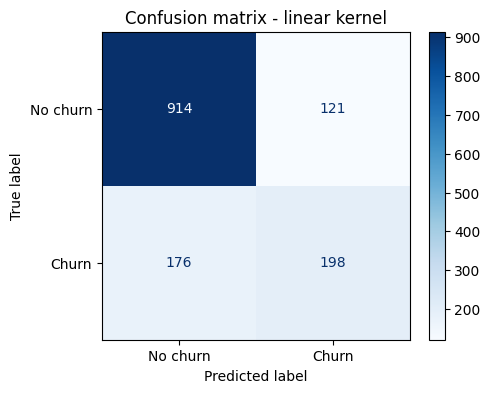

In [11]:
best_kernel = kernel_df['F1'].astype(float).idxmax()
print('Best kernel by F1:', best_kernel)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, models[best_kernel].predict(X_test_s),
                                        display_labels=['No churn', 'Churn'], cmap='Blues', ax=ax)
ax.set_title(f'Confusion matrix - {best_kernel} kernel')
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The linear kernel had the best F1 (0.571), ahead of RBF (0.556) and poly (0.540). RBF had the highest accuracy (0.793) and precision (0.644), but lower recall. This is mildly surprising, since RBF is the more flexible kernel. It makes sense for this data, though: after one-hot encoding the data is high-dimensional (30 features) and the churn signal (contract type, tenure, charges, internet service) is mostly additive, so a linear boundary is already close to what the data supports. The extra flexibility of RBF and poly mostly fits noise. The F1 gaps are also small (about 0.015 to 0.03), so they should not be over-interpreted.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* Poly used the most (2,739), then RBF (2,661), then linear (2,569). All three use roughly 45-49% of the 5,634 training points as support vectors. That is very high and means the classes overlap heavily and many points sit inside or on the wrong side of the margin. The slightly higher count for poly/RBF shows they need a more complex boundary to cover the same overlap without a matching gain in F1.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* Part 4 asks for an RBF search, and RBF is the sensible one to tune. Its default settings already give the best accuracy (0.793) and precision (0.644) and an F1 of 0.556, only 0.015 below linear. Unlike linear, it has a second hyperparameter (gamma) that the grid search can tune to improve recall. Poly is the weakest (F1 0.540) and has the most support vectors. If simplicity alone mattered, linear would be the best choice (F1 0.571 with the fewest support vectors).

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [12]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_s)
print('Explained variance ratio per component:', pca.explained_variance_ratio_.round(4))
print('Total explained variance (2 components): %.4f' % pca.explained_variance_ratio_.sum())

Explained variance ratio per component: [0.3325 0.1198]
Total explained variance (2 components): 0.4523


In [13]:
C_values = [0.01, 1, 100]
svm_2d = {}
for C in C_values:
    m = SVC(kernel='rbf', C=C, gamma='scale', random_state=RANDOM_STATE)
    m.fit(X_train_2d, y_train)
    svm_2d[C] = m
    print(f'C={C:<6} support vectors = {m.support_.shape[0]:5d}   train acc = {m.score(X_train_2d, y_train):.4f}')

C=0.01   support vectors =  2997   train acc = 0.7346
C=1      support vectors =  2659   train acc = 0.7792
C=100    support vectors =  2631   train acc = 0.7813


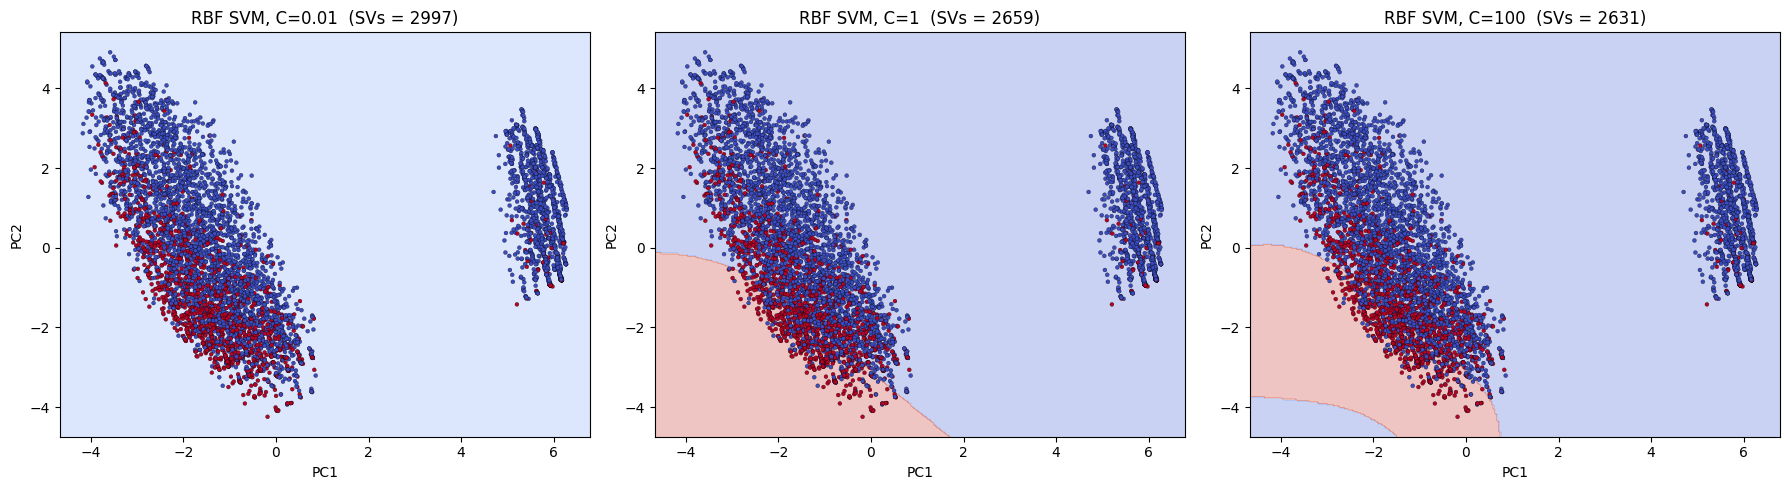

In [14]:
pad = 0.5
x_min, x_max = X_train_2d[:, 0].min() - pad, X_train_2d[:, 0].max() + pad
y_min, y_max = X_train_2d[:, 1].min() - pad, X_train_2d[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, C in zip(axes, C_values):
    Z = svm_2d[C].predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap='coolwarm',
               s=8, edgecolor='k', linewidth=0.2)
    ax.set_title(f'RBF SVM, C={C}  (SVs = {svm_2d[C].support_.shape[0]})')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* At C=0.01 there is no visible boundary: the whole plane is predicted as "no churn". At C=1 a smooth curved region for "churn" appears in the lower-left, where the red points are concentrated. At C=100 the churn region grows and the boundary bends more, with an extra pocket at the bottom-left edge. So larger C gives a more flexible boundary that follows the training points more closely.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* The support-vector count falls as C rises: 2,997 (C=0.01), 2,659 (C=1), 2,631 (C=100). This matches the theory. A small C means a soft margin that tolerates many violations, so many points end up inside the margin and become support vectors. A large C penalises violations heavily, so the margin is narrower and fewer points are support vectors. The drop from C=1 to C=100 is small because the two classes overlap heavily in 2-D.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* C=0.01 underfits: it predicts one class everywhere, and its training accuracy of 0.7346 is about the same as the share of non-churners (73.5%), so it learned nothing beyond the majority class. C=100 is the one closest to overfitting, because its boundary is the most flexible (the extra pocket in the bottom-left corner, in a region with almost no data). The overfitting is mild, though: training accuracy only rises from 0.779 to 0.781 compared with C=1, so C=1 looks like the best balance.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The two principal components keep only 45.2% of the variance (33.3% + 12.0%), so more than half of the information is thrown away. Classes that overlap here may be separable in the full 30-D space, and the real model's boundary and support vectors (a different count) are not the ones in this picture. The plot can make the problem look harder than it is, and it makes the shape of the boundary and the effect of C look different from the real model. Boundary regions in empty parts of the plane are also extrapolation, not something learned from data.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [15]:
param_grid = {'C': [0.1, 1, 10, 100],
              'gamma': [0.0001, 0.001, 0.01, 0.1]}
gs = GridSearchCV(SVC(kernel='rbf', random_state=RANDOM_STATE), param_grid,
                  cv=5, scoring='f1', n_jobs=-1)
t0 = time.time()
gs.fit(X_train_s, y_train)
print('Grid search time: %.1f s' % (time.time() - t0))
print('Best params:', gs.best_params_)
print('Best CV F1 : %.4f' % gs.best_score_)

Grid search time: 91.1 s
Best params: {'C': 100, 'gamma': 0.01}
Best CV F1 : 0.5877


param_gamma  0.0001  0.0010  0.0100  0.1000
param_C                                    
0.1          0.0000  0.0000  0.5417  0.4640
1.0          0.0000  0.5746  0.5650  0.5734
10.0         0.5777  0.5857  0.5853  0.5266
100.0        0.5870  0.5710  0.5877  0.5060


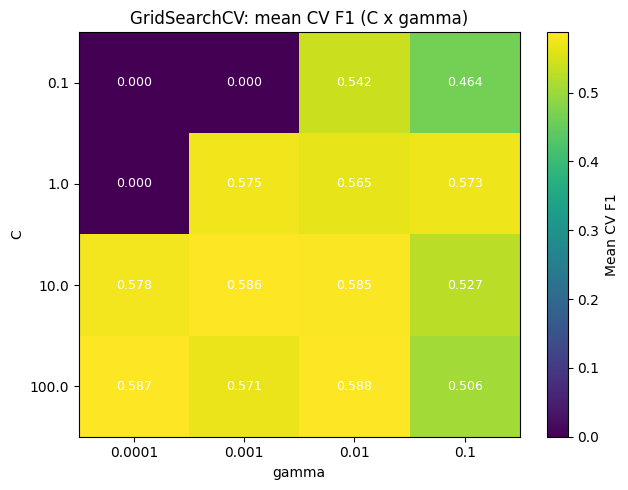

In [16]:
res = pd.DataFrame(gs.cv_results_)
heat = res.pivot(index='param_C', columns='param_gamma', values='mean_test_score').astype(float)
print(heat.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(heat.values, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)));   ax.set_yticklabels(heat.index)
ax.set_xlabel('gamma'); ax.set_ylabel('C')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f'{heat.values[i, j]:.3f}', ha='center', va='center', color='w', fontsize=9)
plt.colorbar(im, label='Mean CV F1'); ax.set_title('GridSearchCV: mean CV F1 (C x gamma)')
plt.tight_layout(); plt.show()

In [17]:
best_svm = gs.best_estimator_            # already refit on the full training set
pred_best = best_svm.predict(X_test_s)
m_tuned = get_metrics(y_test, pred_best)
print('TUNED RBF (test):  ', {k: round(v, 4) for k, v in m_tuned.items()})
print('UNTUNED RBF (test):', {k: round(results['rbf'][k], 4) for k in ['Accuracy','Precision','Recall','F1']})
print('CV F1 vs test F1  : %.4f vs %.4f' % (gs.best_score_, m_tuned['F1']))

TUNED RBF (test):   {'Accuracy': 0.7786, 'Precision': 0.5939, 'Recall': 0.5241, 'F1': 0.5568}
UNTUNED RBF (test): {'Accuracy': 0.7928, 'Precision': 0.6444, 'Recall': 0.4893, 'F1': 0.5562}
CV F1 vs test F1  : 0.5877 vs 0.5568


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* Best C = 100 and gamma = 0.01, with a mean 5-fold CV F1 of 0.5877.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* There is no single sharp peak. A broad plateau of combinations scores about 0.57 to 0.59 (for example C=10 with gamma 0.001 or 0.01 gives 0.586 and 0.585; C=100 with gamma 0.0001 gives 0.587). Weak spots are low C combined with small gamma (F1 = 0, the model predicts only the majority class) and gamma = 0.1 (about 0.46 to 0.57, falling to 0.51 at C=100 as it overfits). So the model is fairly robust once C and gamma are in a sensible range, and the differences between the top combinations are within noise.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* CV F1 was 0.588 and test F1 was 0.557, a gap of about 0.03. That is small and acceptable, and part of it comes from picking the best of 16 combinations on the CV score (an optimistic bias). A much larger gap would suggest overfitting to the training folds or hyperparameter selection, data leakage in CV, or a test set that differs from the training distribution.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* Barely, in terms of F1: tuned 0.5568 vs untuned 0.5562. Accuracy fell from 0.793 to 0.779 and precision fell from 0.644 to 0.594, while recall rose from 0.489 to 0.524. Tuning mainly traded precision for recall, because the default setting was already near the plateau. The real improvement came from handling class imbalance in Part 5, not from the C/gamma search.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


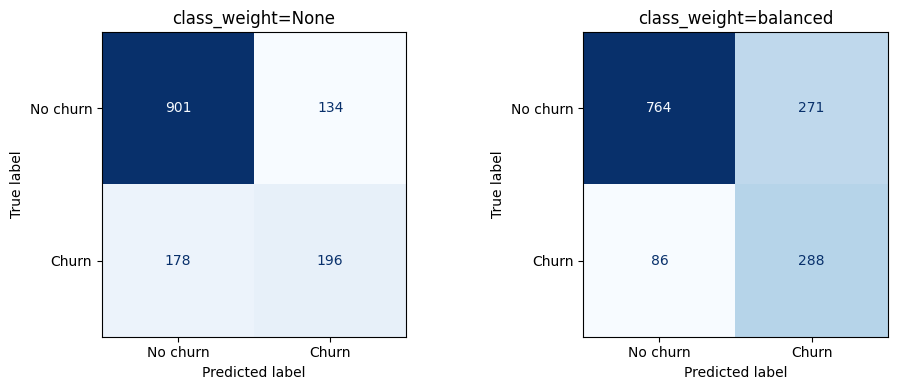

,Accuracy,Precision,Recall,F1
class_weight=None,0.7786,0.5939,0.5241,0.5568
class_weight=balanced,0.7466,0.5152,0.7701,0.6174


In [18]:
best_C, best_gamma = gs.best_params_['C'], gs.best_params_['gamma']
svm_none = SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight=None,
               probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)
svm_bal = SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight='balanced',
              probability=True, random_state=RANDOM_STATE).fit(X_train_s, y_train)

rows = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, mdl) in zip(axes, [('class_weight=None', svm_none), ('class_weight=balanced', svm_bal)]):
    p = mdl.predict(X_test_s)
    rows[name] = get_metrics(y_test, p)
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=['No churn', 'Churn'],
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
cw_df = pd.DataFrame(rows).T.round(4)
cw_df

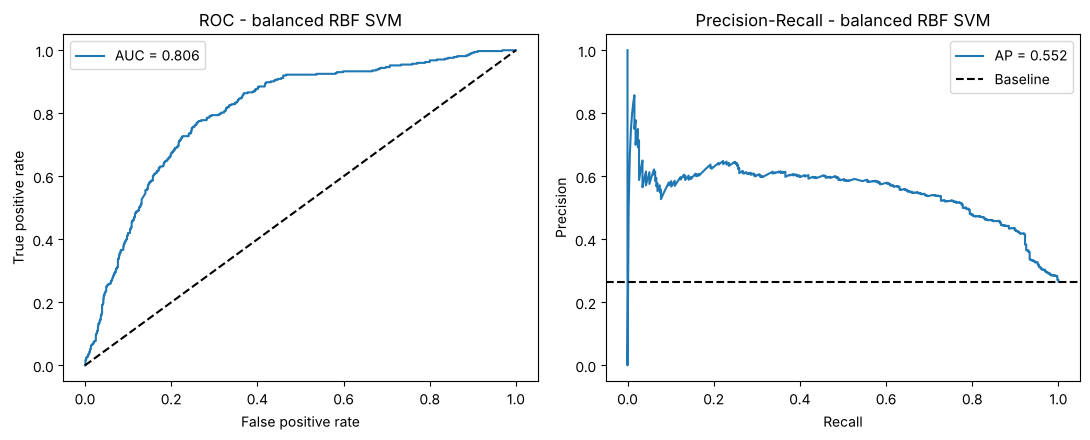

In [ ]:
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_bal)
prec, rec, _ = precision_recall_curve(y_test, proba_bal)
roc_auc = auc(fpr, tpr); ap = average_precision_score(y_test, proba_bal)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}'); axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC - balanced RBF SVM'); axes[0].legend()
axes[1].plot(rec, prec, label=f'AP = {ap:.3f}'); axes[1].axhline(y_test.mean(), color='k', ls='--', label='Baseline')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall - balanced RBF SVM'); axes[1].legend()
plt.tight_layout(); plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Recall rose from 0.5241 to 0.7701 (+0.246), precision fell from 0.5939 to 0.5152 (-0.079), F1 rose from 0.5568 to 0.6174, and accuracy fell from 0.7786 to 0.7466. The balanced model catches many more churners at the cost of more false alarms.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* Missing a churner is usually more costly: the company loses that customer's recurring revenue and the cost of acquiring a replacement, while a false positive only costs a retention offer or discount sent to someone who would have stayed. I would deploy the balanced model, because it finds about 77% of churners versus 52%. The exact trade-off depends on the real cost of the retention offer versus customer lifetime value.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* `probability=True`. This fits an extra Platt-scaling calibration step (using internal cross-validation) on top of the SVM's decision values, which makes training slower. The probabilities can occasionally disagree with `predict()`. (Newer scikit-learn versions warn that this option is deprecated in favour of `CalibratedClassifierCV`.)

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

compare = {}
def run(name, mdl, Xtr, Xte):
    t0 = time.time(); mdl.fit(Xtr, y_train); tt = time.time() - t0
    r = get_metrics(y_test, mdl.predict(Xte)); r['Train time (s)'] = tt
    compare[name] = r

run('Decision Tree', DecisionTreeClassifier(random_state=RANDOM_STATE), X_train, X_test)
run('Random Forest', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), X_train, X_test)
run('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train_s, X_test_s)
run('KNN (k=5)', KNeighborsClassifier(n_neighbors=5), X_train_s, X_test_s)
run('SVM (tuned RBF, balanced)',
    SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight='balanced', random_state=RANDOM_STATE),
    X_train_s, X_test_s)

showdown = pd.DataFrame(compare).T.round(4).sort_values('F1', ascending=False)
showdown

,Accuracy,Precision,Recall,F1,Train time (s)
"SVM (tuned RBF, balanced)",0.7466,0.5152,0.7701,0.6174,3.5404
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.0419
Random Forest,0.7899,0.6336,0.4947,0.5556,1.6634
KNN (k=5),0.7473,0.5253,0.5000,0.5123,0.0020
Decision Tree,0.7417,0.5139,0.4947,0.5041,0.0458


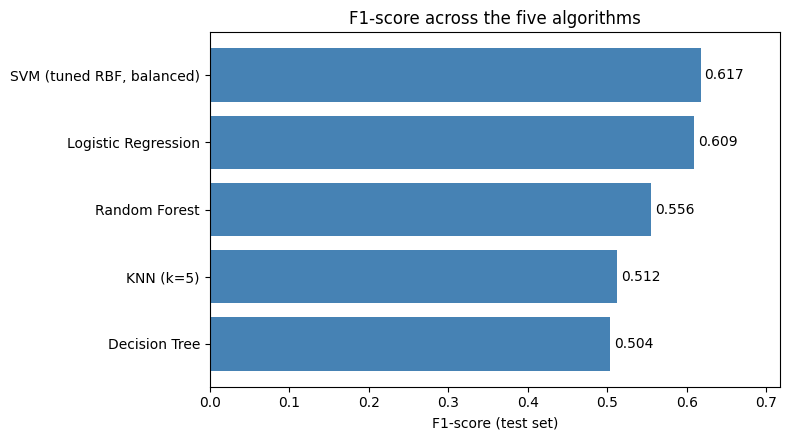

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
s = showdown['F1'].sort_values()
bars = ax.barh(s.index, s.values, color='steelblue')
for b, v in zip(bars, s.values):
    ax.text(v + 0.005, b.get_y() + b.get_height()/2, f'{v:.3f}', va='center')
ax.set_xlabel('F1-score (test set)'); ax.set_title('F1-score across the five algorithms')
ax.set_xlim(0, s.max() + 0.1)
plt.tight_layout(); plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* The balanced tuned SVM wins both: F1 0.617 (Logistic Regression is a close second at 0.609) and recall 0.770 (next best is Logistic Regression at 0.567). Logistic Regression wins on accuracy (0.807) and precision (0.658).

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* The final fit takes about 1.6 s versus 0.02 s for the Decision Tree and 0.7 s for the Random Forest (plus about 39 s for the grid search). Training time is not a real problem for a dataset this size. The extra cost was worth it for the recall gain (0.77 vs about 0.49 for the trees), but note that most of that gain comes from class_weight and not from the SVM itself. Logistic Regression trains in 0.06 s and nearly matches the SVM's F1, so on cost-effectiveness alone it is the main competitor. I did not give the other models class weights, which makes the comparison somewhat unfair to them.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* The balanced tuned RBF SVM: highest F1 (0.617) and highest recall (0.770), which fits the business goal of catching churners. The cost is lower precision (0.515) and accuracy (0.747). If the retention budget is tight and false alarms are expensive, Logistic Regression (F1 0.609, precision 0.658, accuracy 0.807) is the simpler and more interpretable alternative.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [21]:
FINAL_MODEL = svm_bal          # chosen final model (see Part 6 answer c)
final_pred = FINAL_MODEL.predict(X_test_s)
final_proba = FINAL_MODEL.predict_proba(X_test_s)[:, 1]

out = pd.DataFrame({'true_label': y_test.values,
                    'predicted_label': final_pred,
                    'predicted_churn_probability': final_proba.round(4)},
                   index=y_test.index)
out.to_csv('svm_predictions.csv', index_label='row_index')
print('Saved svm_predictions.csv', out.shape)
out.head()

Saved svm_predictions.csv (1409, 3)


,true_label,predicted_label,predicted_churn_probability
437,0,0,0.0606
2280,0,1,0.6042
2235,0,0,0.0402
4460,0,0,0.2548
3761,0,0,0.0390


**Executive Summary**

I recommend the RBF-kernel SVM with C=100, gamma=0.01 and class_weight='balanced', trained on standardised features. On the held-out test set it achieved F1 = 0.617, recall = 0.770, precision = 0.515 and accuracy = 0.747, and it had the best F1 and recall of the five algorithms compared (Logistic Regression was close with F1 = 0.609). Scaling was essential: the unscaled linear SVM reached only 0.598 accuracy, hit the iteration cap and was about 30x slower. Hyperparameter tuning gave almost no F1 gain (0.557 vs 0.556 untuned), while class weighting gave most of the improvement. The main trade-off in Part 5 was giving up about 8 points of precision and 3 points of accuracy to gain about 25 points of recall, because missing a churner is more costly than sending an unneeded retention offer. One limitation is that the comparison is not perfectly fair: the other models were not class-weighted or tuned, and there is a single train/test split, so small differences (such as SVM vs Logistic Regression) may be within noise.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* That the linear kernel had the best F1 of the three kernels, and that tuning C and gamma changed almost nothing, while a single option (class_weight='balanced') raised recall from 0.52 to 0.77.

(b) If you had one more hour, what would you try next?

*Your answer:* I would apply class_weight='balanced' (and tuning) to Logistic Regression, Random Forest and the other models for a fair comparison, tune the decision threshold using the precision-recall curve with an estimated cost per false negative/false positive, and repeat the evaluation with repeated cross-validation to see whether the differences between the top models are real.